<a href="https://colab.research.google.com/github/EngHussain-AlSharari/qafila-margin-project/blob/main/Smart_Real_Estate_Assistant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step-by-Step Generation

⏳ جاري تحميل الـ Tokenizer والنموذج... يرجى الانتظار قليلاً


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

✅ تم تحميل النموذج والـ Tokenizer بنجاح!
--------------------------------------------------
💬 New Inquiry: Where is the real estate sales office
--------------------------------------------------
🏢 Real Estate Inquiry: Where is the real estate sales office
🎯 Top next tokens probabilities:
   ' located'      85.16%
   '?'             4.81%
   ' of'           3.74%
   ' in'           1.07%
   ' on'           0.95%


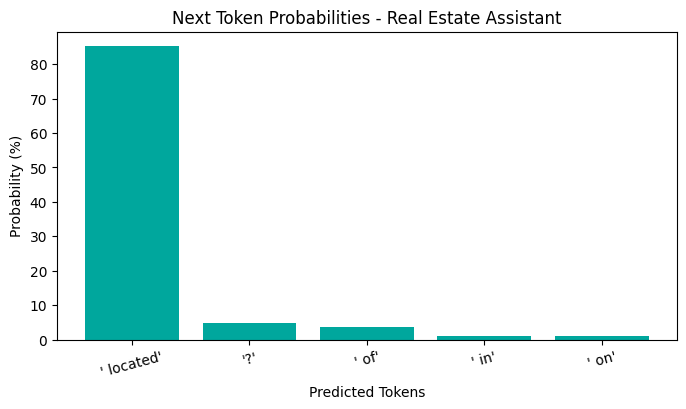

--------------------------------------------------
👣 Step 1: ' located'
👣 Step 2: '?'
👣 Step 3: '<|im_end|>'
👣 Step 4: '\n'
👣 Step 5: '<|startoftext|>'
👣 Step 6: 'L'
🏢 Final Real Estate Text: Where is the real estate sales office located?<|im_end|>
<|startoftext|>L
✅ Real Estate Execution Completed Successfully for Saud


In [61]:
# 1️⃣ تثبيت المكتبات المطلوبة (إذا لم تكن مطبقة مسبقاً)
!pip install -q transformers torch tiktoken matplotlib

# 2️⃣ استيراد المكتبات الأساسية
import torch
import tiktoken
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

# 3️⃣ تعريف معرف النموذج وتحميل الـ Tokenizer والـ Model (هنا يتم تعريف tokenizer و model)
MODEL_ID = "LiquidAI/LFM2.5-350M"

print("⏳ جاري تحميل الـ Tokenizer والنموذج... يرجى الانتظار قليلاً")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.bfloat16
)
model.eval()
print("✅ تم تحميل النموذج والـ Tokenizer بنجاح!")

# 4️⃣ إعداد متغيرات الاستفسار العقاري
new_inquiry = "Where is the real estate sales office"
top_n = 5
generation_steps = 6

# 5️⃣ دالة توقع الـ Token التالي مع الرسم البياني
def show_next_tokens(text, top_n):
    inputs = tokenizer(text, return_tensors="pt")
    with torch.no_grad():
        logits = model(**inputs).logits[0, -1]
    probs = torch.softmax(logits, dim=-1)
    top = torch.topk(probs, top_n)

    words = [tokenizer.decode([i]) for i in top.indices]
    values = [p.item() * 100 for p in top.values]

    print("🏢 Real Estate Inquiry:", text)
    print("🎯 Top next tokens probabilities:")
    for word, value in zip(words, values):
        print(f"   {word!r:<15} {value:.2f}%")

    plt.figure(figsize=(8, 4))
    plt.bar([repr(w) for w in words], values, color="#00A79D")
    plt.title("Next Token Probabilities - Real Estate Assistant")
    plt.ylabel("Probability (%)")
    plt.xlabel("Predicted Tokens")
    plt.xticks(rotation=15)
    plt.show()

# 6️⃣ دالة توليد النص خطوة بخطوة
def generate_step_by_step(text, steps):
    current = text
    for step in range(1, steps + 1):
        inputs = tokenizer(current, return_tensors="pt")
        with torch.no_grad():
            logits = model(**inputs).logits[0, -1]

        next_id = torch.argmax(logits).item()
        next_token = tokenizer.decode([next_id])

        print(f"👣 Step {step}: {next_token!r}")
        current += next_token

    print("🏢 Final Real Estate Text:", current)

# 🚀 7️⃣ تشغيل الدوال بالاستفسار العقاري
print("-" * 50)
print("💬 New Inquiry:", new_inquiry)
print("-" * 50)
show_next_tokens(new_inquiry, top_n)
print("-" * 50)
generate_step_by_step(new_inquiry, generation_steps)
print("✅ Real Estate Execution Completed Successfully for Saud")

Environment Setup

In [62]:
!pip install -q transformers torch

import time
import json
import torch
from threading import Thread
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    TextIteratorStreamer
)

MODEL_ID = "LiquidAI/LFM2.5-350M"
assistant_name = "Smart Real Estate Assistant"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.bfloat16
)
model.eval()

print("🏢 Assistant:", assistant_name)
print("✅ Local model ready for Real Estate:", MODEL_ID)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

🏢 Assistant: Smart Real Estate Assistant
✅ Local model ready for Real Estate: LiquidAI/LFM2.5-350M


Your First Model Call

In [63]:
# 🏢 System Prompt (توجيهات نموذج العقارات الذكي)
system_prompt = """
You are a real estate assistant.
Answer questions about properties, residential and commercial listings, and rentals.
Do not invent prices, locations, or property details.
If information is unavailable, say it is not confirmed.
Do not provide financial advice.
"""

# ❓ Real Estate User Inquiry (استفسار العميل عن العقار)
user_inquiry = "What types of residential properties are currently available for rent?"
max_new_tokens = 80

def ask_model(question):
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": question}
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    )

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    return tokenizer.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

print("🏢 Client:", user_inquiry)
print("🤖 Assistant:", ask_model(user_inquiry))
print("✅ First Real Estate Inquiry Completed Successfully")

🏢 Client: What types of residential properties are currently available for rent?
🤖 Assistant: I don't have access to real-time data on available residential properties for rent. However, I can provide general information about types of residential properties that are commonly available for rent, such as apartments, houses, condos, or single-family homes. Would you like me to share any of these types?
✅ First Real Estate Inquiry Completed Successfully


تجربة عملية لتحليل وتوليد النصوص باستخدام نموذج لغوي LLM & Token

💬 New Inquiry: Where is the real estate sales office
--------------------------------------------------
🏢 Real Estate Inquiry: Where is the real estate sales office
🎯 Top next tokens probabilities:
   ' located'      85.16%
   '?'             4.81%
   ' of'           3.74%
   ' in'           1.07%
   ' on'           0.95%


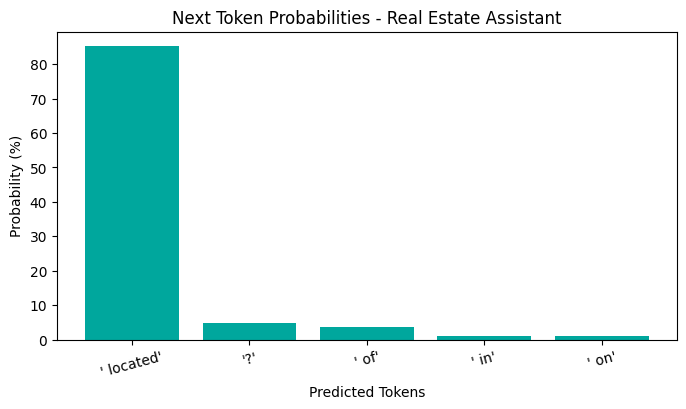

--------------------------------------------------
👣 Step 1: ' located'
👣 Step 2: '?'
👣 Step 3: '<|im_end|>'
👣 Step 4: '\n'
👣 Step 5: '<|startoftext|>'
👣 Step 6: 'L'
🏢 Final Real Estate Text: Where is the real estate sales office located?<|im_end|>
<|startoftext|>L
✅ Real Estate Conversion & Execution Completed Successfully for Saud


In [64]:
# 🏢 تعريف استفسار جديد خاص بالعقارات
new_inquiry = "Where is the real estate sales office"
top_n = 5
generation_steps = 6

# 1️⃣ دالة توقع الـ Token التالي مع الرسم البياني
def show_next_tokens(text, top_n):
    inputs = tokenizer(text, return_tensors="pt")
    with torch.no_grad():
        logits = model(**inputs).logits[0, -1]
    probs = torch.softmax(logits, dim=-1)
    top = torch.topk(probs, top_n)

    words = [tokenizer.decode([i]) for i in top.indices]
    values = [p.item() * 100 for p in top.values]

    print("🏢 Real Estate Inquiry:", text)
    print("🎯 Top next tokens probabilities:")
    for word, value in zip(words, values):
        print(f"   {word!r:<15} {value:.2f}%")

    plt.figure(figsize=(8, 4))
    plt.bar([repr(w) for w in words], values, color="#00A79D")
    plt.title("Next Token Probabilities - Real Estate Assistant")
    plt.ylabel("Probability (%)")
    plt.xlabel("Predicted Tokens")
    plt.xticks(rotation=15)
    plt.show()

# 2️⃣ دالة توليد النص خطوة بخطوة
def generate_step_by_step(text, steps):
    current = text
    for step in range(1, steps + 1):
        inputs = tokenizer(current, return_tensors="pt")
        with torch.no_grad():
            logits = model(**inputs).logits[0, -1]

        # اختيار الـ Token الأعلى احتمالاً (Greedy Decoding)
        next_id = torch.argmax(logits).item()
        next_token = tokenizer.decode([next_id])

        print(f"👣 Step {step}: {next_token!r}")
        current += next_token

    print("🏢 Final Real Estate Text:", current)

# 🚀 تشغيل الدوال بالاستفسار العقاري الجديد
print("💬 New Inquiry:", new_inquiry)
print("-" * 50)
show_next_tokens(new_inquiry, top_n)
print("-" * 50)
generate_step_by_step(new_inquiry, generation_steps)
print("✅ Real Estate Conversion & Execution Completed Successfully for Saud")

Retry Logic

In [65]:
retries = 3
timeout_seconds = 120

def ask_with_retry(question):
    for attempt in range(1, retries + 1):
        try:
            inputs = tokenizer.apply_chat_template(
                [{"role": "system", "content": system_prompt},
                 {"role": "user", "content": question}],
                add_generation_prompt=True,
                return_tensors="pt", return_dict=True
            )
            output = model.generate(**inputs, max_new_tokens=max_new_tokens, max_time=timeout_seconds)
            print(f"✅ Attempt {attempt}: Success")
            return tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
        except Exception as e:
            print(f"⚠️ Attempt {attempt} failed:", e)
    return "Sorry, please try again later."

print("🏢 Smart Real Estate Assistant - Retry Mechanism Active")
print("🔁 Retries:", retries, "| ⏱️ Timeout:", timeout_seconds, "s")
print("🤖 Assistant:", ask_with_retry(user_inquiry))
print("✅ Real Estate Assistant Ready & Tested Successfully")

🏢 Smart Real Estate Assistant - Retry Mechanism Active
🔁 Retries: 3 | ⏱️ Timeout: 120 s
✅ Attempt 1: Success
🤖 Assistant: I don't have access to real-time data on available residential properties for rent. However, I can provide general information about types of residential properties that are commonly available for rent, such as apartments, houses, condos, or single-family homes. Would you like me to share any of these types?
✅ Real Estate Assistant Ready & Tested Successfully


Streaming & TTFT

In [66]:
stream_inquiry = "Explain how to book a property viewing appointment."

inputs = tokenizer.apply_chat_template(
    [{"role": "system", "content": system_prompt},
     {"role": "user", "content": stream_inquiry}],
    add_generation_prompt=True,
    return_tensors="pt", return_dict=True
)
streamer = TextIteratorStreamer(tokenizer, skip_prompt=True, skip_special_tokens=True)

start, first = time.time(), None
Thread(target=model.generate, kwargs={**inputs, "streamer": streamer, "max_new_tokens": max_new_tokens}).start()

print("🏢 Smart Real Estate Assistant - Streaming Response:")
for text in streamer:
    first = first or time.time()
    print(text, end="", flush=True)

print(f"\n\n⚡ TTFT: {(first - start) * 1000:.0f} ms | ⏱️ Total: {time.time() - start:.2f} s")
print("✅ Streaming & Performance Test Completed Successfully")

🏢 Smart Real Estate Assistant - Streaming Response:
I'm not able to provide step-by-step instructions for booking a property viewing appointment. However, I can suggest that you visit the property's official website or contact the real estate agent directly for assistance. They should be able to guide you through the process and provide you with the necessary information to schedule your viewing.

⚡ TTFT: 7742 ms | ⏱️ Total: 35.43 s
✅ Streaming & Performance Test Completed Successfully


Response Caching

In [67]:
cache = {}

def ask_cached(question):
    if question in cache:
        print("⚡ Cache HIT")
        return cache[question]

    print("🔄 Cache MISS")
    answer = ask_with_retry(question)  # نستخدم دالة إعادة المحاولة السابقة لضمان الاستقرار
    cache[question] = answer
    return answer

print("🏢 Smart Real Estate Assistant - Caching Test:")

# التجربة الأولى (سيكون هناك Cache MISS ويقوم بتوليد الإجابة)
start = time.time()
print("🤖 Assistant (1st call):", ask_cached(user_inquiry))
print(f"⏱️ Time: {time.time() - start:.2f} s\n")

# التجربة الثانية بنفس السؤال (سيكون هناك Cache HIT وتظهر الإجابة فوراً)
start = time.time()
print("🤖 Assistant (2nd call - Cached):", ask_cached(user_inquiry))
print(f"⏱️ Time: {time.time() - start:.2f} s")
print("✅ Caching Mechanism Completed Successfully")

🏢 Smart Real Estate Assistant - Caching Test:
🔄 Cache MISS
✅ Attempt 1: Success
🤖 Assistant (1st call): I don't have access to real-time data on available residential properties for rent. However, I can provide general information about types of residential properties that are commonly available for rent, such as apartments, houses, condos, or single-family homes. Would you like me to share any of these types?
⏱️ Time: 16.89 s

⚡ Cache HIT
🤖 Assistant (2nd call - Cached): I don't have access to real-time data on available residential properties for rent. However, I can provide general information about types of residential properties that are commonly available for rent, such as apartments, houses, condos, or single-family homes. Would you like me to share any of these types?
⏱️ Time: 0.00 s
✅ Caching Mechanism Completed Successfully


Handling Failures

In [68]:
def safe_assistant(question, simulate_failure=False):
    try:
        if simulate_failure:
            raise RuntimeError("Model unavailable")

        return ask_model(question)

    except Exception as e:
        print("⚠️ Error:", e)
        return "Sorry, the real estate assistant is temporarily unavailable."

print("🏢 Client:", user_inquiry)
print("🤖 Assistant:", safe_assistant(user_inquiry, simulate_failure=True))
print("✅ Failure Handling & Fallback Test Completed Successfully")

🏢 Client: What types of residential properties are currently available for rent?
⚠️ Error: Model unavailable
🤖 Assistant: Sorry, the real estate assistant is temporarily unavailable.
✅ Failure Handling & Fallback Test Completed Successfully


Pydantic Schema

In [69]:

!pip -q install pydantic

from pydantic import BaseModel, Field, ValidationError

# 🏡 Smart Real Estate Assistant

class RealEstateAppointment(BaseModel):

    customer_name: str = Field(min_length=2)

    property_type: str

    appointment_type: str


# 📝 Customer Data

appointment_data = {

    "customer_name": "Saud",

    "property_type": "Villa",

    "appointment_type": "Property Viewing"

}

try:

    appointment = RealEstateAppointment(**appointment_data)

    print("✅ بيانات الموعد العقاري صحيحة")

    print("🏡 Appointment:", appointment.model_dump())

except ValidationError as e:

    print("❌ خطأ في البيانات")

    print(e)


✅ بيانات الموعد العقاري صحيحة
🏡 Appointment: {'customer_name': 'Saud', 'property_type': 'Villa', 'appointment_type': 'Property Viewing'}


Tool Schema

In [70]:

appointment_tool = {
    "type": "function",
    "function": {
        "name": "check_property_appointment",
        "description": "Check real estate property appointment information",
        "parameters": {
            "type": "object",
            "properties": {
                "customer_name": {"type": "string"},
                "property_type": {"type": "string"}
            },
            "required": ["customer_name", "property_type"]
        }
    }
}

print("✅ Tool Schema Ready")
print("🔧 Tool:", appointment_tool["function"]["name"])
print("📝 Description:", appointment_tool["function"]["description"])
print("📋 Required:", appointment_tool["function"]["parameters"]["required"])


✅ Tool Schema Ready
🔧 Tool: check_property_appointment
📝 Description: Check real estate property appointment information
📋 Required: ['customer_name', 'property_type']


Two-Call Pattern

In [71]:

# 🏡 Sample real estate data

properties = {

    ("Saud", "Size"): "Villa Size: 350 SQM",

    ("Saud", "Price"): "Villa Price: 1,200,000 SAR",

    ("Saud", "House Facade"): "Modern Exterior Design"

}

# 🔧 Tool execution

def check_property(customer_name, property_type):

    return properties.get(
        (customer_name, property_type),
        "Property information not found"
    )


# 💬 User request

customer_name = "Saud"

property_type = "Price"

print("💬 Customer:", customer_name)

print("🔧 Tool:", appointment_tool["function"]["name"])

# 1️⃣ Simulated tool request

print("📤 Tool Call: check_property")

# 2️⃣ Execute tool and return result

result = check_property(customer_name, property_type)

print("📥 Tool Result:", result)

print("🤖 Assistant:", f"Property information: {result}")


💬 Customer: Saud
🔧 Tool: check_property_appointment
📤 Tool Call: check_property
📥 Tool Result: Villa Price: 1,200,000 SAR
🤖 Assistant: Property information: Villa Price: 1,200,000 SAR


ToolRegistry

In [72]:

# 🏡 Real Estate tools

def list_property_services():

    return ["Size", "Price", "House Facade"]


# 🔧 Register tools

tool_registry = {

    "check_property": check_property,

    "list_property_services": list_property_services

}


# 💬 Select tool

selected_tool = "list_property_services"


# ▶️ Execute

result = tool_registry[selected_tool]()


print("✅ ToolRegistry Ready")

print("🧰 Available Tools:", list(tool_registry.keys()))

print("🔧 Selected Tool:", selected_tool)

print("📥 Tool Result:", result)


✅ ToolRegistry Ready
🧰 Available Tools: ['check_property', 'list_property_services']
🔧 Selected Tool: list_property_services
📥 Tool Result: ['Size', 'Price', 'House Facade']


Parallel Tool Calls

In [73]:

import asyncio
import time

# 🔧 Run a tool asynchronously

async def run_tool(tool_name, *args):

    await asyncio.sleep(1)  # Simulated delay

    return await asyncio.to_thread(
        tool_registry[tool_name], *args
    )


# 🏡 Run real estate tools in parallel

start = time.perf_counter()

property_info, property_services = await asyncio.gather(

    run_tool("check_property", "Saud", "Price"),

    run_tool("list_property_services")

)

elapsed = time.perf_counter() - start


print("✅ Parallel Calls Completed")

print("🏡 Property Information:", property_info)

print("📋 Property Services:", property_services)

print(f"⏱️ Total Time: {elapsed:.2f} s")


✅ Parallel Calls Completed
🏡 Property Information: Villa Price: 1,200,000 SAR
📋 Property Services: ['Size', 'Price', 'House Facade']
⏱️ Total Time: 1.01 s


Integration Testing

In [74]:

# 🏡 Smart Real Estate Assistant

test_cases = [

    ("check_property", ["Saud", "Price"]),

    ("list_property_services", []),

    ("unknown_tool", [])

]

# 🧪 Test registered tools

for tool_name, args in test_cases:

    print(f"\n🔧 Testing: {tool_name}")

    if tool_name in tool_registry:

        result = tool_registry[tool_name](*args)

        print("✅ Status: Success")

        print("📥 Result:", result)

    else:

        print("❌ Status: Tool Not Found")


print("\n🏁 Real Estate Lab Testing Completed")



🔧 Testing: check_property
✅ Status: Success
📥 Result: Villa Price: 1,200,000 SAR

🔧 Testing: list_property_services
✅ Status: Success
📥 Result: ['Size', 'Price', 'House Facade']

🔧 Testing: unknown_tool
❌ Status: Tool Not Found

🏁 Real Estate Lab Testing Completed


Vector Storage & Semantic Search

In [75]:
import re
from dataclasses import dataclass

# 🏢 Real Estate Document (مستند العقارات)
real_estate_text = """
Residential: Apartments and villas for rent and sale.
Commercial: Offices and retail shops in prime locations.
Land: Residential and commercial plots available.
"""

# 🧹 Clean Text (تنظيف النص وإزالة المسافات الزائدة)
clean_text = re.sub(r"\s+", " ", real_estate_text).strip()

# 📄 Document Model (نموذج المستند)
@dataclass
class Document:
    source: str
    content: str

# إنشاء كائن المستند الخاص بالعقارات
document = Document(
    source="real_estate_listings",
    content=clean_text
)

print("🏢 Project: Smart Real Estate Assistant")
print("📄 Source:", document.source)
print("🧹 Cleaned Text:", document.content)
print("✅ Document Ready")

🏢 Project: Smart Real Estate Assistant
📄 Source: real_estate_listings
🧹 Cleaned Text: Residential: Apartments and villas for rent and sale. Commercial: Offices and retail shops in prime locations. Land: Residential and commercial plots available.
✅ Document Ready


Embeddings & Output Validation

In [76]:
!pip -q install sentence-transformers

import numpy as np
from sentence_transformers import SentenceTransformer

# 🏢 Real Estate Chunks (أجزاء نصوص العقارات)
recursive_chunks = [
    "Residential: Apartments and villas for rent and sale in various locations.",
    "Commercial: Offices, retail shops, and commercial buildings available.",
    "Land: Residential and commercial plots ready for investment."
]

# 🧠 Load embedding model
model = SentenceTransformer("all-MiniLM-L6-v2")

# 🔢 Convert real estate chunks to embeddings
embeddings = model.encode(recursive_chunks)

# 📊 Results
print("🏢 Project: Smart Real Estate Assistant")
print("🧩 Total Chunks:", len(recursive_chunks))
print("🔢 Total Embeddings:", len(embeddings))
print("📐 Vector Dimensions:", embeddings.shape[1])
print("🔍 Sample Vector:", embeddings[0][:5].round(3))
print("✅ Validation:", len(embeddings) == len(recursive_chunks))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

🏢 Project: Smart Real Estate Assistant
🧩 Total Chunks: 3
🔢 Total Embeddings: 3
📐 Vector Dimensions: 384
🔍 Sample Vector: [ 0.094 -0.055 -0.028  0.092 -0.042]
✅ Validation: True


Embeddings

In [77]:
!pip -q install sentence-transformers huggingface_hub

import numpy as np
from sentence_transformers import SentenceTransformer

# 🏢 Real Estate Chunks (أجزاء نصوص العقارات)
recursive_chunks = [
    "Residential: Apartments and villas for rent and sale in various locations.",
    "Commercial: Offices, retail shops, and commercial buildings available.",
    "Land: Residential and commercial plots ready for investment."
]

# 🧠 Load embedding model
# (ملاحظة: يمكنك وضع الـ token الخاص بك هنا إذا كان لديك حساب في Hugging Face، أو تجاهله إذا كنت تريد فقط إخفاء التحذير محلياً)
model = SentenceTransformer("all-MiniLM-L6-v2", token=False)

# 🔢 Convert real estate chunks to embeddings
embeddings = model.encode(recursive_chunks)

# 📊 Results
print("🏢 Project: Smart Real Estate Assistant")
print("🧩 Total Chunks:", len(recursive_chunks))
print("🔢 Total Embeddings:", len(embeddings))
print("📐 Vector Dimensions:", embeddings.shape[1])
print("🔍 Sample Vector:", embeddings[0][:5].round(3))
print("✅ Validation:", len(embeddings) == len(recursive_chunks))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

🏢 Project: Smart Real Estate Assistant
🧩 Total Chunks: 3
🔢 Total Embeddings: 3
📐 Vector Dimensions: 384
🔍 Sample Vector: [ 0.094 -0.055 -0.028  0.092 -0.042]
✅ Validation: True


Recursive Chunking

In [78]:
!pip -q install langchain-text-splitters

from langchain_text_splitters import RecursiveCharacterTextSplitter

# ⚙️ Settings (إعدادات التقسيم)
splitter = RecursiveCharacterTextSplitter(
    chunk_size=60,
    chunk_overlap=0,
    separators=[". ", " ", ""]
)

# ✂️ Split Real Estate Document (تقسيم مستند العقارات)
recursive_chunks = splitter.split_text(document.content)

# 📊 Results (النتائج)
print("🏢 Project: Smart Real Estate Assistant")
print("🧩 Recursive Chunks:", len(recursive_chunks))

for i, chunk in enumerate(recursive_chunks, 1):
    print(f"📄 Chunk {i}: {chunk}")

print("✅ Recursive Chunking Completed")

🏢 Project: Smart Real Estate Assistant
🧩 Recursive Chunks: 3
📄 Chunk 1: Residential: Apartments and villas for rent and sale
📄 Chunk 2: . Commercial: Offices and retail shops in prime locations
📄 Chunk 3: . Land: Residential and commercial plots available.
✅ Recursive Chunking Completed


RAG Service

In [79]:
# 🏢 RAG Service (خدمة الاسترجاع المعزز بالتوليد للعقارات)
def rag_service(question):

    # 🔍 Retrieve (استرجاع النص الأقرب للمعنى من قاعدة بيانات العقارات)
    query_vector = model.encode([question]).tolist()
    results = collection.query(
        query_embeddings=query_vector,
        n_results=1
    )

    # 📄 Augment (تجهيز السياق المسترجع)
    context = results["documents"][0][0]

    # 🤖 Generate (توليد الرد المبني على معلومات العقارات)
    answer = f"Based on real estate information: {context}"

    return context, answer

# ❓ Client Question (سؤال العميل/المشتري)
question = "Where can I find apartments and villas for rent?"

# ▶️ Run RAG (تشغيل الخدمة)
context, answer = rag_service(question)

# 📊 Results (طباعة النتائج)
print("🏢 Project: Smart Real Estate Assistant")
print("❓ Question:", question)
print("📄 Retrieved Context:", context)
print("🤖 Assistant Answer:", answer)
print("✅ RAG Service Completed")

🏢 Project: Smart Real Estate Assistant
❓ Question: Where can I find apartments and villas for rent?
📄 Retrieved Context: Residential: Apartments and villas for rent and sale
🤖 Assistant Answer: Based on real estate information: Residential: Apartments and villas for rent and sale
✅ RAG Service Completed


Retrieval Evaluation

In [80]:
# 🏆 Golden Dataset (مجموعة بيانات الاختبار للعقارات)
tests = [
    ("apartments and villas for rent", "Residential"),
    ("offices and retail shops", "Commercial"),
    ("plots available for investment", "Land")
]

# 📊 Evaluation (عملية التقييم وحساب دقة الاسترجاع)
hits, scores = 0, []

for question, expected in tests:
    vector = model.encode([question]).tolist()
    results = collection.query(query_embeddings=vector, n_results=3)
    documents = results["documents"][0]

    rank = next((i for i, doc in enumerate(documents, 1)
                 if expected.lower() in doc.lower()), None)

    hits += rank is not None
    scores.append(1 / rank if rank else 0)

    print(f"❓ {question} | 🎯 {expected} | 📍 Rank: {rank}")

print(f"🏢 Project: Smart Real Estate Assistant Evaluation")
print(f"✅ Hit Rate@3: {hits/len(tests):.0%}")
print(f"📊 MRR@3: {sum(scores)/len(tests):.2f}")
print("✅ Evaluation Completed Successfully")

❓ apartments and villas for rent | 🎯 Residential | 📍 Rank: 1
❓ offices and retail shops | 🎯 Commercial | 📍 Rank: 1
❓ plots available for investment | 🎯 Land | 📍 Rank: 1
🏢 Project: Smart Real Estate Assistant Evaluation
✅ Hit Rate@3: 100%
📊 MRR@3: 1.00
✅ Evaluation Completed Successfully


Metadata Filters & Output Validation

In [81]:
# 🏷️ Add Metadata (إضافة البيانات الوصفية لأقسام العقارات)
real_estate_departments = ["Residential", "Commercial", "Land"]

collection.update(
    ids=[f"chunk_{i}" for i in range(len(recursive_chunks))],
    metadatas=[
        {"department": next((d for d in real_estate_departments if d in chunk), "Unknown")}
        for chunk in recursive_chunks
    ]
)

# 🔍 Search & Validate (البحث والتصفية حسب القسم العقاري والتحقق)
department = "Residential"
vector = model.encode(["apartments and villas for rent"]).tolist()

result = collection.query(
    query_embeddings=vector,
    where={"department": department},
    n_results=1
)

docs = result["documents"][0]

print("🏢 Real Estate Department:", department)
print("🔍 Retrieved:", docs[0] if docs else "No results")
print("✅ Validation:", "Passed" if docs else "Failed")
print("✅ Metadata Filtering Completed Successfully")

🏢 Real Estate Department: Residential
🔍 Retrieved: Residential: Apartments and villas for rent and sale
✅ Validation: Passed
✅ Metadata Filtering Completed Successfully


SQLite Session

In [82]:
import sqlite3

# 🏢 Create Real Estate Database
conn = sqlite3.connect("real_estate.db")
conn.execute("""
CREATE TABLE IF NOT EXISTS chat (
    question TEXT,
    answer TEXT
)
""")

# 💬 Save Real Estate Conversation
conn.execute("DELETE FROM chat")
conn.execute(
    "INSERT INTO chat VALUES (?, ?)",
    ("Where are the residential villas located?", "Residential Department - Al-Narjis District")
)
conn.commit()

# 📊 Retrieve Real Estate Conversation
for question, answer in conn.execute("SELECT * FROM chat"):
    print("👤 Client:", question)
    print("🤖 Assistant:", answer)

print("✅ Real Estate Session Saved Successfully")
conn.close()

👤 Client: Where are the residential villas located?
🤖 Assistant: Residential Department - Al-Narjis District
✅ Real Estate Session Saved Successfully


Sliding Window

In [83]:
# 🏢 Smart Real Estate Assistant

# 💬 Client Conversation (قائمة استفسارات العميل العقارية)
messages = [
    "Where are the residential villas located?",
    "What is commercial real estate?",
    "Are property viewing hours open 24/7?",
    "How can I book a property viewing appointment?",
    "Where is the real estate sales office?"
]

# 🪟 Sliding Window (نافذة التمرير للاحتفاظ بآخر الرسائل)
window_size = 5
recent_messages = messages[-window_size:]

# 📊 Results (عرض النتائج والمحادثات الأخيرة)
print("🏢 Smart Real Estate Assistant")
print("💬 Total Messages:", len(messages))
print("🪟 Recent Messages:")

for message in recent_messages:
    print("✅", message)

print("✅ Sliding Window Mechanism Completed Successfully for Saud")

🏢 Smart Real Estate Assistant
💬 Total Messages: 5
🪟 Recent Messages:
✅ Where are the residential villas located?
✅ What is commercial real estate?
✅ Are property viewing hours open 24/7?
✅ How can I book a property viewing appointment?
✅ Where is the real estate sales office?
✅ Sliding Window Mechanism Completed Successfully for Saud


Recursive Summarisation

In [84]:
# 🏢 Smart Real Estate Assistant

# 💬 Client Conversation (قائمة استفسارات العميل العقارية)
messages = [
    "I need a consultation for a residential villa.",
    "I want to check the Commercial Department listings.",
    "Do I need an appointment for property viewing?",
    "Can I book a viewing for Sunday?",
    "What time should I arrive at the sales office?"
]

# 📝 Manual Summary (الملخص اليدوي/التدريجي للمحادثة العقارية)
summary = "Client wants a residential villa viewing appointment on Sunday."

# 📊 Results (عرض النتائج والملخص)
print("🏢 Smart Real Estate Assistant")
print("💬 Total Messages:", len(messages))
print("📝 Summary:", summary)
print("✅ Real Estate Summary Completed Successfully")

🏢 Smart Real Estate Assistant
💬 Total Messages: 5
📝 Summary: Client wants a residential villa viewing appointment on Sunday.
✅ Real Estate Summary Completed Successfully


Fidelity Gate + Hybrid Compactor

In [85]:
# 🏢 Smart Real Estate Assistant

messages = [
    "I need a residential property in Al-Narjis.",
    "Can I book a viewing for Sunday?",
    "What time should I arrive at the office?"
]

# 📝 Summary (ملخص تفاصيل حجز المعاينة العقارية)
summary = "Residential property viewing appointment on Sunday"

# ✅ Fidelity Gate (بوابة التحقق من وجود الكلمات الرئيسية الهامة في الملخص)
important_info = ["Residential", "Sunday"]
valid = all(word in summary for word in important_info)

# 🔄 Hybrid Compactor (دمج الملخص مع آخر رسالتين من المحادثة العقارية)
compact = [summary] + messages[-2:]

# 📊 Results (عرض النتائج النهائية)
print("🏢 Smart Real Estate Assistant")
print("✅ Fidelity Gate:", "Passed" if valid else "Failed")
print("💬 Original Messages:", len(messages))
print("📝 Compact Context:", compact)
print("✅ Real Estate Fidelity Gate & Compactor Completed Successfully for Saud")

🏢 Smart Real Estate Assistant
✅ Fidelity Gate: Passed
💬 Original Messages: 3
📝 Compact Context: ['Residential property viewing appointment on Sunday', 'Can I book a viewing for Sunday?', 'What time should I arrive at the office?']
✅ Real Estate Fidelity Gate & Compactor Completed Successfully for Saud


Infinite Loop

In [86]:
# 🏢 Smart Real Estate Assistant

question = "Where are the residential villas located?"
max_steps = 5

# 🔄 Simulate Repeated Calls (محاكاة التكرار المستمر لنفس الاستفسار العقاري)
for step in range(max_steps):
    print(f"🔄 Step {step + 1}: {question}")

print("⚠️ Repeated Real Estate Calls Detected")
print("✅ Loop Detection & Handling Completed Successfully for Saud")

🔄 Step 1: Where are the residential villas located?
🔄 Step 2: Where are the residential villas located?
🔄 Step 3: Where are the residential villas located?
🔄 Step 4: Where are the residential villas located?
🔄 Step 5: Where are the residential villas located?
⚠️ Repeated Real Estate Calls Detected
✅ Loop Detection & Handling Completed Successfully for Saud


LoopDetector

In [87]:
# 🏢 Smart Real Estate Assistant

questions = [
    "Where are the residential villas located?",
    "Where is the commercial sales office?",
    "Where are the residential villas located?"
]

# 🔍 Loop Detector (مكتشف التكرار)
seen = set()

for question in questions:
    if question in seen:
        print("⚠️ Loop Detected:", question)
        break

    seen.add(question)
    print("✅ Processing:", question)

print("✅ Real Estate Loop Detection & Prevention Completed Successfully for Saud")

✅ Processing: Where are the residential villas located?
✅ Processing: Where is the commercial sales office?
⚠️ Loop Detected: Where are the residential villas located?
✅ Real Estate Loop Detection & Prevention Completed Successfully for Saud


@observe + Trace Tree

In [88]:
# 🏢 Smart Real Estate Assistant

# 🔍 Simple Tracing Decorator (ديكور لتتبع خطوات المعالجة)
def observe(func):
    def wrapper(question):
        print("🔍 Trace Started")
        result = func(question)
        print("✅ Trace Completed")
        return result
    return wrapper

@observe
def real_estate_assistant(question):
    print("  └── Processing Real Estate Inquiry:", question)
    return "Residential Department - Al-Narjis District"

# ▶️ Run (تنفيذ التتبع للاستفسار العقاري)
question = "Where are the residential villas located?"
print("🤖 Answer:", real_estate_assistant(question))
print("✅ Real Estate Tracing Completed Successfully for Saud")

🔍 Trace Started
  └── Processing Real Estate Inquiry: Where are the residential villas located?
✅ Trace Completed
🤖 Answer: Residential Department - Al-Narjis District
✅ Real Estate Tracing Completed Successfully for Saud


DeepEval — Evaluation

In [89]:
# 🏢 Smart Real Estate Assistant

# 🧪 Evaluation Data (بيانات تقييم الاستفسار العقاري)
question = "Where are the residential villas located?"
expected = "Residential Department - Al-Narjis District"
answer = "Residential Department - Al-Narjis District"

# ✅ Evaluate Answer (تقييم مطابقة الإجابة)
score = 1 if answer == expected else 0

# 📊 Results (عرض نتائج التقييم)
print("❓ Question:", question)
print("🤖 Answer:", answer)
print("🎯 Expected:", expected)
print("📊 Score:", score)
print("✅ Evaluation:", "Passed" if score == 1 else "Failed")
print("✅ Real Estate Evaluation Completed Successfully for Saud")

❓ Question: Where are the residential villas located?
🤖 Answer: Residential Department - Al-Narjis District
🎯 Expected: Residential Department - Al-Narjis District
📊 Score: 1
✅ Evaluation: Passed
✅ Real Estate Evaluation Completed Successfully for Saud


لوحة تحكم تفاعلية للمساعد العقاري الذكي (Smart Real Estate Assistant Dashboard)

In [90]:
"""Smart Real Estate Assistant - dashboard UI (chat + map + listing). Single file - works in Colab & plain Python."""
import html, random
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ---- RAG backend (knowledge base + TF-IDF retriever + cache) ----
KB = [
    ("Residential", "Apartments and villas for rent and sale in various locations."),
    ("Commercial",  "Offices, retail shops, and commercial buildings available."),
    ("Land",        "Residential and commercial plots available for investment."),
    ("Viewing",     "Property viewing appointments are booked in advance, Sunday to Thursday."),
]
vec = TfidfVectorizer(ngram_range=(1, 2), stop_words="english")
X = vec.fit_transform([t for _, t in KB])
_cache = {}

def ask(q):
    if q not in _cache:
        s = cosine_similarity(vec.transform([q]), X)[0]
        i = int(np.argmax(s))
        _cache[q] = KB[i][1] if s[i] > 0.05 else "Not confirmed."
    return _cache[q]

# ---- data (sample listings, Riyadh) ----
LISTINGS = [
    dict(title="Al-Narjis, Riyadh", desc="Modern 350 sqm villa, 5 bedrooms, 4 bathrooms, private garden.", price="1,200,000 SAR", src="Sample data", xy=(0.50, 0.42), top=True),
    dict(title="Al-Yasmin, Riyadh",  desc="Family apartment, 3 bed / 2 bath, 165 sqm.", price="780,000 SAR", src="Sample data", xy=(0.58, 0.36)),
    dict(title="Al-Malqa, Riyadh",   desc="Townhouse, 4 bedrooms, close to schools.",   price="1,050,000 SAR", src="Sample data", xy=(0.44, 0.50)),
    dict(title="Hittin, Riyadh",     desc="Duplex villa, 4 bed / 3 bath.",              price="1,150,000 SAR", src="Sample data", xy=(0.62, 0.56)),
]
SCORES = [("Overall", 78, "#4c8dff"), ("Schools", 81, "#2ecc71"), ("Safety", 75, "#4c8dff")]
CHAT = [("bot", "Hi! I can help you find a home. Where would you like to live?"),
        ("user", "Show me villas for rent."),
        ("bot", ask("Where are villas for rent?")),
        ("user", "Can I book a viewing?"),
        ("bot", ask("Can I book a viewing?"))]
cur = LISTINGS[0]

def svg_map(w=640, h=520):
    random.seed(4); s = [f'<svg viewBox="0 0 {w} {h}" width="100%" height="100%"><rect width="{w}" height="{h}" fill="#10151f"/>']
    for i in range(0, w, 70): s.append(f'<line x1="{i}" y1="0" x2="{i-90}" y2="{h}" stroke="#1f2837" stroke-width="{2+i%3}"/>')
    for j in range(0, h, 60): s.append(f'<line x1="0" y1="{j}" x2="{w}" y2="{j+25}" stroke="#1f2837" stroke-width="{2+j%3}"/>')
    cx, cy = w*cur["xy"][0], h*cur["xy"][1]
    s.append(f'<circle cx="{cx}" cy="{cy}" r="190" fill="rgba(76,141,255,.06)" stroke="#4c8dff" stroke-dasharray="6 6"/>')
    for k, (dx, dy) in enumerate([(-90, 110), (110, 90), (60, -120)]):   # routes to points of interest
        s.append(f'<polyline points="{cx},{cy} {cx+dx},{cy} {cx+dx},{cy+dy}" fill="none" stroke="#9b6bff" stroke-width="2.5"/>')
        s.append(f'<circle cx="{cx+dx}" cy="{cy+dy}" r="9" fill="#e74c3c" stroke="#fff"/>')
    for l in LISTINGS:
        x, y = w*l["xy"][0], h*l["xy"][1]; c = "#2ecc71" if l.get("top") else "#f39c12"
        s.append(f'<circle cx="{x}" cy="{y}" r="11" fill="{c}" stroke="#fff" stroke-width="2"/>')
    s.append(f'<text x="{cx-28}" y="{cy-22}" fill="#fff" font-size="12" font-weight="700">Top result</text></svg>')
    return "".join(s)

def build():
    chat = "".join(f'<div class="b {r}">{html.escape(t)}</div>' for r, t in CHAT)
    cards = "".join(f'<div class="card"><small>{n.upper()}</small><b style="color:{c}">{v}<span>/100</span></b>'
                    f'<i><u style="width:{v}%;background:{c}"></u></i></div>' for n, v, c in SCORES)
    return f"""<div class="app" dir="ltr"><style>
    .app{{font-family:Inter,Segoe UI,sans-serif;background:#0b0f17;color:#e8ecf4;display:grid;grid-template-columns:270px 1fr 270px;grid-template-rows:auto 1fr;gap:12px;padding:12px;height:560px;border-radius:12px}}
    .app *{{box-sizing:border-box}} .chat{{grid-row:1/3;background:#121826;border-radius:12px;padding:14px;display:flex;flex-direction:column;gap:8px;overflow:auto}}
    .chat h3{{margin:0 0 6px}} .b{{padding:10px 12px;border-radius:12px;font-size:13px;max-width:90%}}
    .bot{{background:#1b2336}} .user{{background:#2563eb;align-self:flex-end}}
    .in{{margin-top:auto;display:flex;gap:6px}} .in div{{flex:1;background:#1b2336;padding:9px;border-radius:8px;color:#7d889e;font-size:13px}} .in span{{background:#2563eb;padding:9px 12px;border-radius:8px;font-size:13px}}
    .top{{display:flex;gap:10px}} .card{{flex:1;background:#121826;border-radius:10px;padding:10px 12px}} .card small{{color:#8b95aa;font-size:10px}}
    .card b{{display:block;font-size:22px}} .card b span{{font-size:11px;color:#8b95aa}} .card i{{display:block;height:4px;background:#232c40;border-radius:3px;margin-top:6px}} .card u{{display:block;height:4px;border-radius:3px}}
    .map{{border-radius:12px;overflow:hidden;background:#10151f;position:relative}}
    .pill{{position:absolute;left:12px;top:12px;background:#1b2336cc;padding:6px 12px;border-radius:8px;font-size:12px}}
    .det{{grid-row:1/3;grid-column:3;background:#121826;border-radius:12px;padding:14px;border:1px solid #1f6b4a;display:flex;flex-direction:column;gap:10px}}
    .img{{height:130px;border-radius:8px;background:linear-gradient(135deg,#2b3a55,#5b7aa8 60%,#c9d6ea);position:relative}}
    .img:after{{content:"";position:absolute;left:20%;bottom:0;width:60%;height:55%;background:#e9edf3;border-radius:4px 4px 0 0}}
    .tag{{position:absolute;left:8px;top:8px;background:#16a34a;font-size:11px;padding:3px 8px;border-radius:12px;z-index:2}}
    .det h4{{margin:0;font-size:16px}} .det p{{margin:0;color:#9aa5ba;font-size:12px}}
    .btn{{padding:10px;border-radius:8px;text-align:center;font-size:13px;font-weight:600}}
    </style>
    <div class="chat"><h3>Smart Real Estate Assistant</h3>{chat}<div class="in"><div>Type a message...</div><span>Send</span></div></div>
    <div class="top">{cards}<div class="card"><small>AVG LISTING</small><b>3,429<span> SAR/sqm</span></b></div></div>
    <div class="map">{svg_map()}<div class="pill">Next listing (1/{len(LISTINGS)}) · 📍 Riyadh</div></div>
    <div class="det"><div class="img"><span class="tag">★ LISTING 1/{len(LISTINGS)}</span></div>
      <h4>{cur['title']}</h4><p>{cur['desc']}</p><p>Source: {cur['src']}</p><p>Price: <b style="color:#4ade80">{cur['price']}</b></p>
      <div class="btn" style="background:#16a34a">View Full Listing →</div><div class="btn" style="background:#6d4aff">Book a Viewing 📅</div></div></div>"""

if __name__ == "__main__":
    page = build()
    open("dashboard.html", "w", encoding="utf-8").write(f"<body style='margin:0;background:#05070b'>{page}</body>")
    try:                                   # inside Colab / Jupyter
        from IPython.display import HTML, display; display(HTML(page))
    except Exception: print("Saved dashboard.html")